# Prime search with threads: performance of the four variants

This notebook compares the four variants by **run time**. Each one finds every prime from 1 to *y* using *x* threads:

| Variant | Printing | Task division |
|---|---|---|
| **V1** | Immediately, with thread id and timestamp | Straight division of the range 1–y into x blocks |
| **V2** | After all threads are joined | Straight division of the range 1–y into x blocks |
| **V3** | Immediately, with thread id and timestamp | Linear search; the divisors of each number are split across x threads |
| **V4** | After all threads are joined | Linear search; the divisors of each number are split across x threads |

**How the data was collected.** `run_benchmarks.py` builds every variant in Release mode (`-O2`) and runs each one over a grid of thread counts and limits. Each config is repeated (5 times for y ≤ 100,000, 3 times above), and the charts use the **median**. The times are the ones the programs print themselves, from just before the threads start to the end of the run. Program output went to a file rather than a terminal, because terminal printing is slow enough to drown out the threading effects.

Divisibility testing (V3 and V4) syncs all threads once per number, so it stops at y = 1,000,000. At y = 10,000,000 with 128 threads, one run would take minutes.

To regenerate the data, run `python3 analysis/run_benchmarks.py` from the repository root, then rerun this notebook.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from IPython.display import display

RESULTS = Path("results")
system = json.loads((RESULTS / "system.json").read_text())
timings = pd.read_csv(RESULTS / "timings.csv")
finish = pd.read_csv(RESULTS / "thread_finish.csv")
interleave = pd.read_csv(RESULTS / "interleaving.csv")

print(f"CPU:       {system['cpu']} ({system['logical_cpus']} logical CPUs)")
print(f"OS:        {system['os']}")
print(f"Compiler:  {system['compiler']}")
print(f"Benchmarked on {system['date']}: {len(timings)} runs")

CPU:       AMD Ryzen 7 9700X 8-Core Processor (16 logical CPUs)
OS:        Linux-6.18.50-2-lts-x86_64-with-glibc2.44
Compiler:  c++ (GCC) 16.2.1 20260810
Benchmarked on 2026-10-10T00:31:15: 464 runs


In [2]:
# Chart style: light surface, hairline grid, thin marks. Each variant keeps the
# same color and marker in every chart, so the marker identifies it without color.
SURFACE, TEXT, TEXT_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
VARIANT = {
    1: dict(name="V1 · immediate · straight",     color="#2a78d6", marker="o"),
    2: dict(name="V2 · deferred · straight",      color="#eb6834", marker="s"),
    3: dict(name="V3 · immediate · divisibility", color="#1baf7a", marker="^"),
    4: dict(name="V4 · deferred · divisibility",  color="#eda100", marker="D"),
}
PART_COLORS = {"Search": "#2a78d6", "Printing": "#eb6834"}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10,
    "text.color": TEXT, "axes.labelcolor": TEXT_2, "xtick.color": TEXT_2, "ytick.color": TEXT_2,
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.axisbelow": True, "axes.titlelocation": "left",
    "lines.linewidth": 2, "lines.markersize": 6, "legend.frameon": False,
})

def threads_axis(ax):
    ax.set_xscale("log", base=2)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}"))
    ax.set_xlabel("Threads (x)")

def plain_log(axis):
    axis.set_major_locator(mticker.LogLocator(base=10, subs=(1, 2, 5)))
    axis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.10g}"))
    axis.set_minor_formatter(mticker.NullFormatter())

def ms_axis(ax, label="Time (ms, log scale)"):
    ax.set_yscale("log")
    plain_log(ax.yaxis)
    ax.set_ylabel(label)

def mark_cores(ax):
    # Hardware threads available: past this, threads take turns on the CPUs.
    cpus = system["logical_cpus"]
    ax.axvline(cpus, color=TEXT_2, linewidth=0.8, zorder=0)
    ax.annotate(f"{cpus} logical CPUs", (cpus, 1), xycoords=("data", "axes fraction"),
                xytext=(4, -4), textcoords="offset points", va="top", fontsize=8, color=TEXT_2)

def plot_variant(ax, frame, variant, y="total_ms", **kw):
    style = VARIANT[variant]
    ax.plot(frame["threads"], frame[y], color=style["color"], marker=style["marker"],
            label=style["name"], markeredgecolor=SURFACE, markeredgewidth=1.5, **kw)

fmt_limit = lambda y: f"{y:,}"

# Median of the repetitions for every (variant, threads, limit).
median = (timings.groupby(["variant", "limit", "threads"], as_index=False)
                 [["total_ms", "search_ms"]].median())
median["print_ms"] = median["total_ms"] - median["search_ms"]
spread = timings.groupby(["variant", "limit", "threads"])["total_ms"].agg(lambda s: s.max() / s.min())
print(f"Repetitions agree closely: the median config's slowest run is {spread.median():.2f}× its fastest.")

Repetitions agree closely: the median config's slowest run is 1.07× its fastest.


## 1. Run time for every config

Median total time in milliseconds. Empty cells are configs that weren't run (divisibility testing above y = 1,000,000).

In [3]:
table = median.pivot_table(index=["limit", "threads"], columns="variant", values="total_ms")
table.columns = [f"V{v}" for v in table.columns]
table.index = table.index.set_levels([table.index.levels[0].map(fmt_limit), table.index.levels[1]])
display(table.style.format("{:,.1f}", na_rep="—").set_caption("Median total time (ms)"))

## 2. How the number of threads affects run time (learning objective a)

One panel per search limit. The y axis is logarithmic because the variants differ by orders of magnitude.

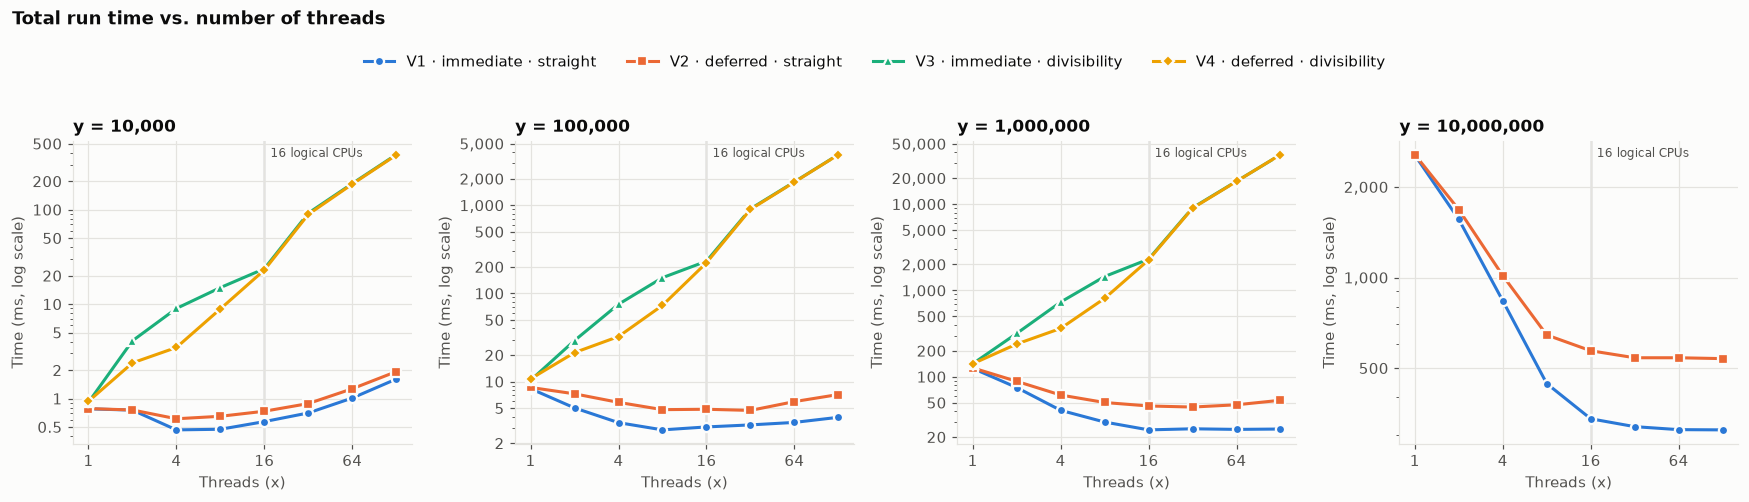

In [4]:
limits = sorted(median["limit"].unique())
fig, axes = plt.subplots(1, len(limits), figsize=(4 * len(limits), 4), sharey=False)
for ax, limit in zip(np.atleast_1d(axes), limits):
    for v in VARIANT:
        frame = median[(median.variant == v) & (median.limit == limit)]
        if not frame.empty:
            plot_variant(ax, frame, v)
    threads_axis(ax); ms_axis(ax); mark_cores(ax)
    ax.set_title(f"y = {fmt_limit(limit)}")
handles, labels = np.atleast_1d(axes)[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.06))
fig.suptitle("Total run time vs. number of threads", x=0.01, ha="left", y=1.13, fontweight="bold")
fig.tight_layout()
plt.show()

**What the chart shows**

- **Straight division (V1, V2) speeds up with more threads, up to the CPU's limit.** At y = 10,000,000, V1 drops from 2,552 ms on 1 thread to 444 ms on 8 and 339 ms on 16. Past 16 threads (this machine's logical CPU count) the line goes flat: 312 ms at 128 threads. There are no more CPUs to run the extra threads on.
- **For small y, threads don't pay for themselves.** At y = 10,000 every straight-division run finishes in under 2 ms, and 128 threads (1.6 ms) is slower than 4 threads (0.5 ms). Creating and joining threads costs more than the little work each one gets.
- **Divisibility testing (V3, V4) gets slower with every thread added, at every y.** At y = 1,000,000, V4 takes 141 ms on 1 thread, 2,257 ms on 16 and 37,508 ms on 128. Each number has only √n divisors to test (at most 1,000 here). Splitting so little work across threads costs far more in coordination than it saves.

### Speedup over one thread

Speedup = time with 1 thread ÷ time with *x* threads, for the largest limit each variant ran. Above 1 the extra threads help; below 1 they make the run slower. The gray line is perfect scaling (x threads give x times the speed).

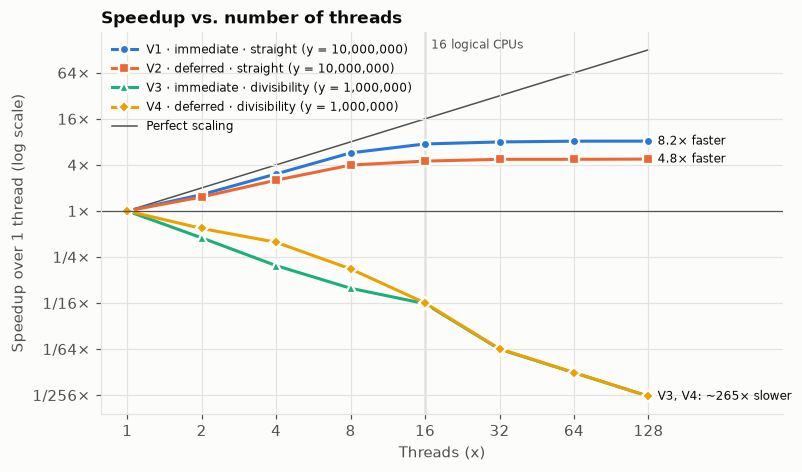

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
final_speedup = {}
for v in VARIANT:
    limit = median[median.variant == v]["limit"].max()
    frame = median[(median.variant == v) & (median.limit == limit)].copy()
    frame["speedup"] = frame["total_ms"].iloc[0] / frame["total_ms"]
    style = VARIANT[v]
    ax.plot(frame["threads"], frame["speedup"], color=style["color"], marker=style["marker"],
            markeredgecolor=SURFACE, markeredgewidth=1.5,
            label=f"{style['name']} (y = {fmt_limit(limit)})")
    last = frame.iloc[-1]
    final_speedup[v] = last.speedup
    if v in (1, 2):
        text = f"{last.speedup:.1f}× faster"
    elif v == 4:  # V3 ends on the same point, so one label covers both
        slowdown = (1 / final_speedup[3] + 1 / final_speedup[4]) / 2
        text = f"V3, V4: ~{slowdown:,.0f}× slower"
    else:
        continue
    ax.annotate(text, (last.threads, last.speedup), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=8, color=TEXT)
xs = np.array(sorted(median["threads"].unique()))
ax.plot(xs, xs, color=TEXT_2, linewidth=1, label="Perfect scaling", zorder=0)
threads_axis(ax); mark_cores(ax)
ax.set_yscale("log", base=2)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(
    lambda v, _: f"{v:g}×" if v >= 1 else f"1/{1 / v:g}×"))
ax.set_xticks(xs)
ax.set_xlim(right=xs.max() * 3.5)  # room for the end labels
ax.set_ylabel("Speedup over 1 thread (log scale)")
ax.axhline(1, color=TEXT_2, linewidth=0.8)
ax.set_title("Speedup vs. number of threads")
ax.legend(loc="upper left", fontsize=8)
plt.show()

**Reading the speedup chart**

- **V1 reaches 8.2× on 128 threads** (y = 10,000,000), and almost all of it comes by 16 threads (7.5×). That is below perfect scaling for two reasons. The 16 logical CPUs are 8 physical cores with 2 hardware threads each, and the blocks are unevenly loaded (see section 5).
- **V2 reaches only 4.8×**: its search scales like V1's, but printing all 664,579 primes after the join is single-threaded and takes about 245 ms no matter how many threads searched.
- **V3 and V4 fall below 1× as soon as a second thread is added**, and keep falling: at 128 threads they are about 265 times slower than on one thread (V3 264.9×, V4 265.5×).

## 3. Task division schemes compared (learning objective d)

Run time as the search limit grows, at a fixed thread count. The two straight-division variants (V1 and V2) and the two divisibility variants (V3 and V4) form two separate groups.

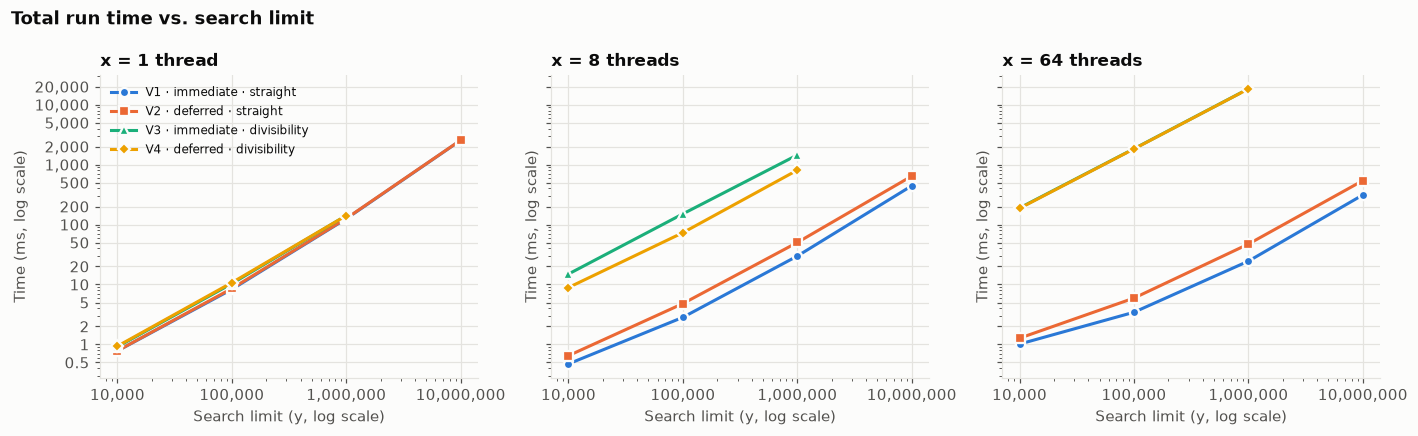

In [6]:
fixed_threads = [1, 8, 64]
fig, axes = plt.subplots(1, len(fixed_threads), figsize=(13, 4), sharey=True)
for ax, x in zip(axes, fixed_threads):
    for v in VARIANT:
        frame = median[(median.variant == v) & (median.threads == x)]
        style = VARIANT[v]
        ax.plot(frame["limit"], frame["total_ms"], color=style["color"], marker=style["marker"],
                markeredgecolor=SURFACE, markeredgewidth=1.5, label=style["name"])
    ax.set_xscale("log"); ms_axis(ax)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.set_xlabel("Search limit (y, log scale)")
    ax.set_title(f"x = {x} thread{'s' if x > 1 else ''}")
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Total run time vs. search limit", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

In [7]:
# How much slower is divisibility testing than straight division, same x and y?
both = median[median.limit <= system["max_divisibility_limit"]]
ratio = (both[both.variant == 4].set_index(["limit", "threads"])["total_ms"]
         / both[both.variant == 2].set_index(["limit", "threads"])["total_ms"]).unstack("threads")
ratio.index = ratio.index.map(fmt_limit)
display(ratio.style.format("{:,.1f}×").set_caption("V4 time ÷ V2 time (both print at the end)"))

threads,1,2,4,8,16,32,64,128
limit,,,,,,,,
"10,000",1.2×,3.2×,5.7×,13.7×,31.3×,100.7×,146.8×,196.4×
"100,000",1.3×,2.9×,5.6×,15.3×,45.9×,190.5×,308.7×,524.9×
"1,000,000",1.1×,2.7×,5.9×,16.1×,49.3×,201.5×,388.1×,703.3×


**Straight division vs. divisibility testing**

- **With 1 thread, the two schemes are close**, because both run the same trial division. At y = 1,000,000, V2 takes 127 ms and V4 takes 141 ms. V4's extra time is the per-number bookkeeping (the shared flag and the barrier, even with a single thread).
- **With more threads the gap grows quickly**: V4 is 6× slower than V2 at 4 threads, 16× at 8, 49× at 16 and about 700× at 128.
- **Why:** straight division gives each thread a large independent block. It never talks to the other threads until the final join. Divisibility testing makes every thread meet at a barrier after *every* number, which is y − 1 meetings per run. On top of that, each thread's share of a number's divisors is tiny (√1,000,000 = 1,000 divisors split x ways).

## 4. Printing immediately vs. at the end

Each pair below uses the same task division, so the only difference is when the primes are printed. A ratio above 1 means printing immediately was slower.

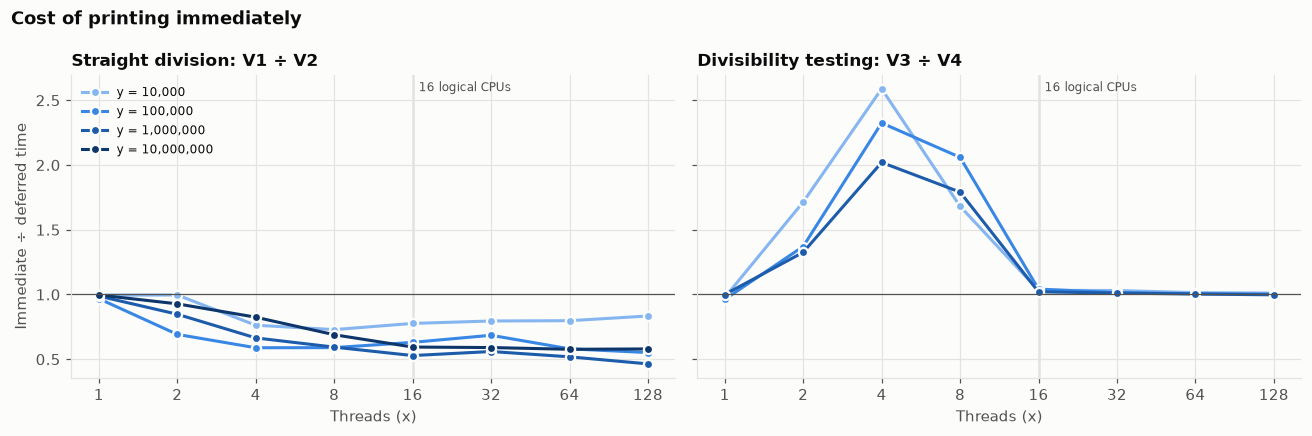

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
pairs = [(1, 2, "Straight division: V1 ÷ V2"), (3, 4, "Divisibility testing: V3 ÷ V4")]
for ax, (immediate, deferred, title) in zip(axes, pairs):
    for limit in sorted(median[median.variant == immediate]["limit"].unique()):
        a = median[(median.variant == immediate) & (median.limit == limit)].set_index("threads")["total_ms"]
        b = median[(median.variant == deferred) & (median.limit == limit)].set_index("threads")["total_ms"]
        r = (a / b).dropna()
        ax.plot(r.index, r.values, marker="o", markeredgecolor=SURFACE, markeredgewidth=1.5,
                label=f"y = {fmt_limit(limit)}",
                color=["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"][[10_000, 100_000, 1_000_000, 10_000_000].index(limit)])
    ax.axhline(1, color=TEXT_2, linewidth=0.8)
    threads_axis(ax); mark_cores(ax)
    ax.set_title(title)
axes[0].set_ylabel("Immediate ÷ deferred time")
axes[0].legend(fontsize=8, loc="upper left")
fig.suptitle("Cost of printing immediately", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

### Where the deferred variants spend their time

V2 and V4 report how long the search took (until every thread was joined) separately from the total. The difference is the main thread printing the primes it collected.

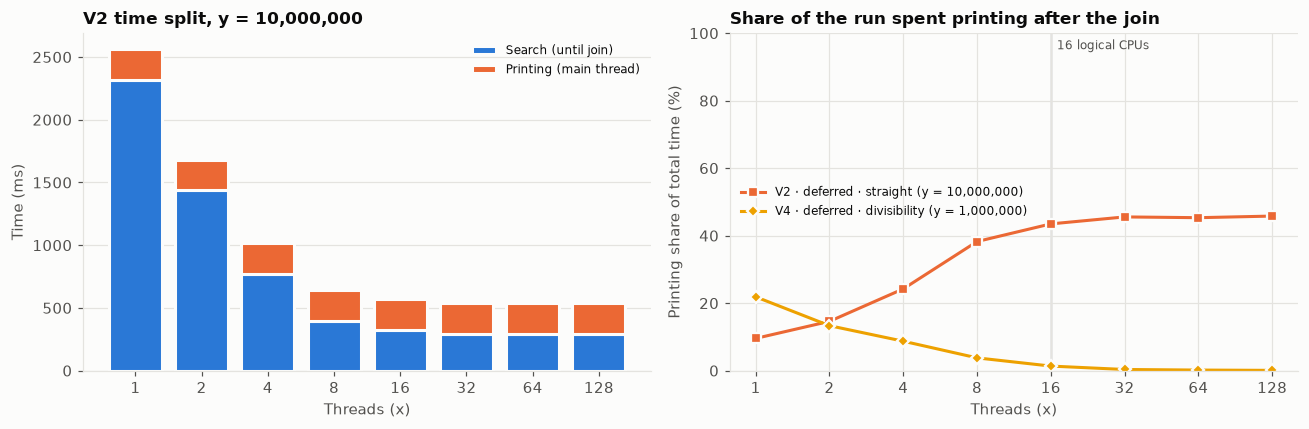

In [9]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4))
limit = median[median.variant == 2]["limit"].max()
frame = median[(median.variant == 2) & (median.limit == limit)]
labels = frame["threads"].astype(str)
left.bar(labels, frame["search_ms"], color=PART_COLORS["Search"], label="Search (until join)",
         edgecolor=SURFACE, linewidth=2)
left.bar(labels, frame["print_ms"], bottom=frame["search_ms"], color=PART_COLORS["Printing"],
         label="Printing (main thread)", edgecolor=SURFACE, linewidth=2)
left.set_xlabel("Threads (x)"); left.set_ylabel("Time (ms)")
left.grid(axis="x", visible=False)
left.set_title(f"V2 time split, y = {fmt_limit(limit)}")
left.legend(fontsize=8)

for v in (2, 4):
    limit_v = median[median.variant == v]["limit"].max()
    frame_v = median[(median.variant == v) & (median.limit == limit_v)].copy()
    frame_v["print_share"] = 100 * frame_v["print_ms"] / frame_v["total_ms"]
    style = VARIANT[v]
    right.plot(frame_v["threads"], frame_v["print_share"], color=style["color"], marker=style["marker"],
               markeredgecolor=SURFACE, markeredgewidth=1.5,
               label=f"{style['name']} (y = {fmt_limit(limit_v)})")
threads_axis(right); mark_cores(right)
right.set_ylim(0, 100); right.set_ylabel("Printing share of total time (%)")
right.set_title("Share of the run spent printing after the join")
right.legend(fontsize=8, loc="center left")
fig.tight_layout()
plt.show()

**When primes are printed**

- **Straight division: printing immediately is faster with many threads.** On 1 thread V1 and V2 tie (2,552 ms vs. 2,562 ms at y = 10,000,000). On 128 threads V1 takes 312 ms and V2 538 ms. V1's threads write their lines while the other threads keep searching, so printing overlaps with the search. V2 prints everything from the main thread after the join, a fixed ~245 ms that more threads can't shrink (the orange part of the bars, which grows to over 40% of V2's run time).
- **Divisibility testing: printing immediately is slower with 2–8 threads** (V3 733 ms vs. V4 363 ms at y = 1,000,000, 4 threads). V3 prints inside the barrier's completion step, while every other thread waits, so each print adds directly to the critical path. From 16 threads up, the barrier itself dominates and the two variants take the same time.
- In V4 printing is a negligible part of the run (the right chart): the search, not the printing, is what's slow.

These runs wrote to a file. A terminal is much slower to print to, which would make the printing cost, and the advantage of overlapping it, far larger.

## 5. Bottlenecks in joining threads (learning objective c)

### Straight division: the join waits for the slowest block

V2 records when each thread started and finished. Every block holds the same count of numbers, but bigger numbers take longer to test, so the threads with the high blocks finish last. The main thread's `join()` cannot return until the slowest one is done.

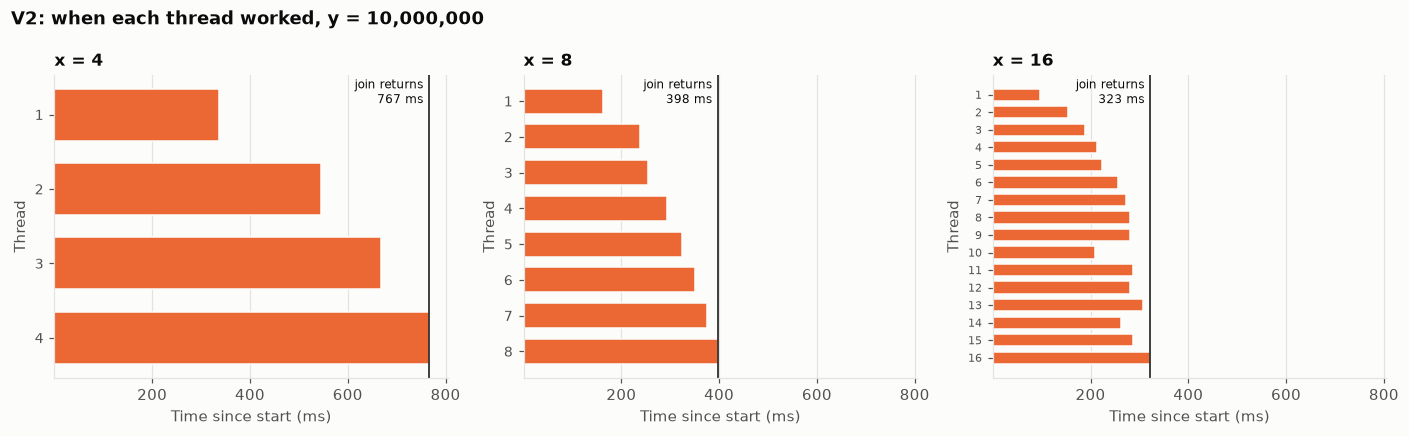

In [10]:
limit = finish["limit"].max()
shown = [x for x in (4, 8, 16) if x in finish["threads"].unique()]
fig, axes = plt.subplots(1, len(shown), figsize=(4.3 * len(shown), 4), sharex=True)
for ax, x in zip(np.atleast_1d(axes), shown):
    run = finish[(finish.limit == limit) & (finish.threads == x)].sort_values("thread")
    ax.barh(run["thread"], run["finish_ms"] - run["start_ms"], left=run["start_ms"],
            color=VARIANT[2]["color"], height=0.7, edgecolor=SURFACE, linewidth=1)
    join = run["finish_ms"].max()
    ax.axvline(join, color=TEXT, linewidth=1)
    ax.annotate(f"join returns\n{join:,.0f} ms", (join, 1.0), xycoords=("data", "axes fraction"),
                xytext=(-4, -2), textcoords="offset points", ha="right", va="top", fontsize=8)
    ax.invert_yaxis()
    ax.set_yticks(run["thread"]); ax.set_ylabel("Thread"); ax.set_xlabel("Time since start (ms)")
    ax.tick_params(axis="y", labelsize=7 if x > 8 else 9)
    ax.grid(axis="y", visible=False)
    ax.set_title(f"x = {x}")
fig.suptitle(f"V2: when each thread worked, y = {fmt_limit(limit)}", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

In [11]:
# Idle share: fraction of the thread-time between start and join that threads spent
# finished and waiting, i.e. capacity lost to the uneven blocks.
def idle_share(run):
    join = run["finish_ms"].max()
    return 1 - (run["finish_ms"] - run["start_ms"]).sum() / (len(run) * join)

balance = (finish.groupby(["limit", "threads"])
                 .apply(lambda run: pd.Series({
                     "fastest thread (ms)": run["finish_ms"].min(),
                     "slowest thread (ms)": run["finish_ms"].max(),
                     "slowest ÷ fastest": run["finish_ms"].max() / run["finish_ms"].min(),
                     "idle while waiting for join": idle_share(run),
                 }), include_groups=False)
                 .reset_index())
big = balance[(balance.limit == limit) & (balance.threads > 1)]
display(big.style.format({"limit": "{:,}", "fastest thread (ms)": "{:,.1f}", "slowest thread (ms)": "{:,.1f}",
                          "slowest ÷ fastest": "{:.2f}×", "idle while waiting for join": "{:.0%}"})
           .hide(axis="index").set_caption(f"V2 load balance, y = {fmt_limit(limit)}"))

limit,threads,fastest thread (ms),slowest thread (ms),slowest ÷ fastest,idle while waiting for join
"10,000,000",2,880.8,"1,436.4",1.63×,19%
"10,000,000",4,336.9,766.7,2.28×,24%
"10,000,000",8,162.5,397.7,2.45×,25%
"10,000,000",16,96.9,322.6,3.33×,24%
"10,000,000",32,66.0,293.0,4.44×,25%
"10,000,000",64,32.9,295.4,8.98×,33%
"10,000,000",128,10.5,292.0,27.72×,51%


**The join waits for the slowest thread**

- Every block holds the same count of numbers, but numbers near y need more divisors tested than numbers near 1. So in the charts above (y = 10,000,000, up to 16 threads), **thread 1 finishes first and the thread with the highest block finishes last**. With small y or more threads than logical CPUs, the order gets noisier: when each thread starts, and when the operating system lets it run, matters as much as the block it got.
- At y = 10,000,000 with 8 threads, the fastest thread is done after 163 ms, but `join()` returns only when the slowest finishes at 398 ms (2.4× later). **25% of the threads' combined time is spent finished and idle**, waiting for the join.
- More threads make the imbalance worse: at 128 threads the slowest thread takes 28× as long as the fastest, and **51% of capacity is idle**. Part of that is the CPU running out: 128 threads take turns on 16 logical CPUs, so some threads start late.
- A fix would be to hand out smaller chunks dynamically (a work queue), or to interleave the numbers (thread k tests k, k + x, k + 2x, …). Both change the required "straight division" scheme, so they're not used here.

### Divisibility testing: one barrier per number

V3 and V4 keep the same x threads for the whole run, but every number ends with a barrier where all x threads must arrive before any can continue. That's y − 1 synchronizations. Dividing the run time by the count of numbers gives the average cost of one round (testing a number plus the barrier).

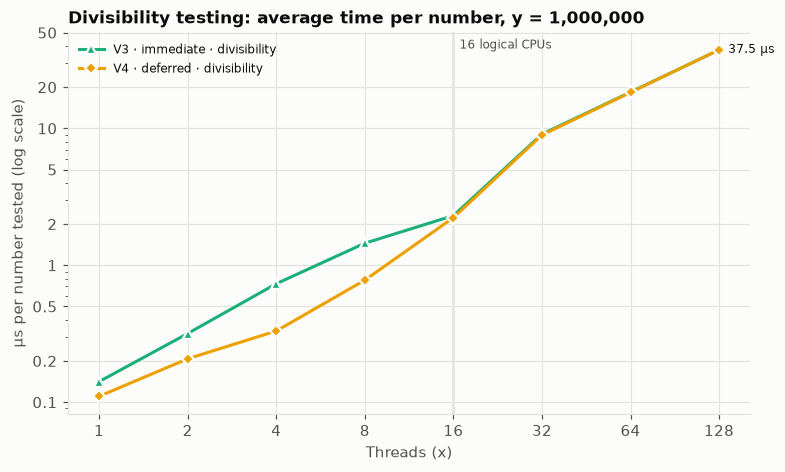

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for v in (3, 4):
    limit = median[median.variant == v]["limit"].max()
    frame = median[(median.variant == v) & (median.limit == limit)].copy()
    frame["us_per_number"] = frame["search_ms" if v == 4 else "total_ms"] * 1000 / (limit - 1)
    plot_variant(ax, frame, v, y="us_per_number")
    if v == 3:
        continue  # V3 ends on the same point as V4, so one label covers both
    last = frame.iloc[-1]
    ax.annotate(f"{last.us_per_number:.1f} µs", (last.threads, last.us_per_number),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=8)
threads_axis(ax); mark_cores(ax)
ax.set_yscale("log"); plain_log(ax.yaxis)
ax.set_ylabel("µs per number tested (log scale)")
ax.set_title(f"Divisibility testing: average time per number, y = {fmt_limit(limit)}")
ax.legend(fontsize=8, loc="upper left")
plt.show()

**The cost of synchronizing on every number**

- With 1 thread, testing a number takes about **0.11 µs** on average. With 16 threads it takes **2.2 µs**, with 32 threads **8.9 µs**, and with 128 threads **37.5 µs**, about 340 times longer.
- Up to 16 threads, the cost grows because all threads must arrive at the barrier and be woken again for every number. Past **16 threads** (more threads than logical CPUs) the cost jumps: from 16 to 32 threads the time per number quadruples. Some threads aren't running when a round starts, and the operating system has to schedule each of them before the barrier can open.
- This is the joining bottleneck in its most extreme form: the threads spend almost all their time waiting for each other, not testing divisors.
- An earlier version created and joined x new threads for every number instead of reusing them with a barrier. It took 22 s for x = 16, y = 200,000 (vs. 0.45 s with the barrier). Creating threads is far more expensive than syncing them.

## 6. Interleaving of output (learning objective b)

In V1 every thread prints its primes as it finds them, so lines from different threads mix in the output. The chart shows the first 300 prime lines of one run: each dot is a printed line, placed at the thread that printed it.

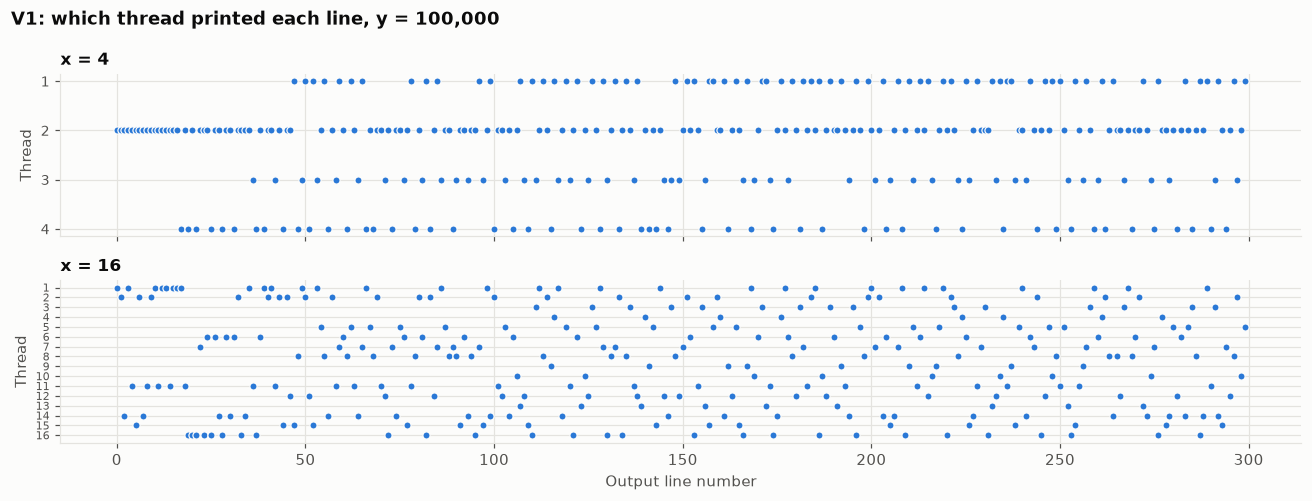

In [13]:
sample_limit = interleave["limit"].max()
shown = [x for x in (4, 16) if x in interleave["threads"].unique()]
fig, axes = plt.subplots(len(shown), 1, figsize=(12, 2.2 + 1.2 * len(shown)), sharex=True)
for ax, x in zip(np.atleast_1d(axes), shown):
    run = interleave[(interleave.threads == x) & (interleave.limit == sample_limit)].sort_values("line").head(300)
    ax.scatter(run["line"], run["thread"], s=22, color=VARIANT[1]["color"], edgecolor=SURFACE, linewidth=0.8)
    ax.set_yticks(range(1, x + 1)); ax.tick_params(axis="y", labelsize=7 if x > 8 else 9)
    ax.set_ylabel("Thread"); ax.invert_yaxis()
    ax.set_title(f"x = {x}")
np.atleast_1d(axes)[-1].set_xlabel("Output line number")
fig.suptitle(f"V1: which thread printed each line, y = {fmt_limit(sample_limit)}", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

In [14]:
def interleave_stats(run):
    run = run.sort_values("line")
    return pd.Series({
        "prime lines": len(run),
        "thread switches": (run["thread"].diff().fillna(0) != 0).sum(),
        "lines out of numeric order": (run["prime"].diff().fillna(1) < 0).sum(),
        "lines out of timestamp order": (run["time_s"].diff().fillna(0) < 0).sum(),
    })

stats = (interleave[interleave.limit == sample_limit].groupby("threads")
         .apply(interleave_stats, include_groups=False).astype(int).reset_index())
display(stats.style.hide(axis="index").format("{:,}")
             .set_caption(f"V1 output order, y = {fmt_limit(sample_limit)}"))

threads,prime lines,thread switches,lines out of numeric order,lines out of timestamp order
1,"9,592",0,0,0
2,"9,592","7,665","3,832",80
4,"9,592","9,215","4,630",816
8,"9,592","9,425","4,689","2,302"
16,"9,592","9,455","4,749","3,619"
32,"9,592","9,452","4,750","4,005"
64,"9,592","9,518","4,695","4,073"
128,"9,592","9,579","4,730","4,207"


**What the interleaving shows**

- **With one thread** the output is in perfect order: 0 thread switches, 0 lines out of order.
- **With 4 threads**, 9,215 of the 9,592 lines (96%) come from a different thread than the line before. The threads take turns at the output lock in an unpredictable order, so the primes appear scrambled: 4,630 lines show a smaller number than the line before.
- **Timestamps can also go backwards** (816 lines with 4 threads, 4,207 with 128). Each thread takes its timestamp *before* waiting for the output lock. A thread that waited longer prints after a thread that found its prime later.
- Lines are never cut in half, because each one is built first and written while holding the mutex. Without the lock, characters from different threads could mix inside a single line.

## 7. Summary

| | Best case | Scaling with threads | Main bottleneck |
|---|---|---|---|
| **V1** · immediate · straight | **312 ms** at y = 10M, 128 threads (8.2× vs. 1 thread) | Good up to the 16 logical CPUs, flat after | Uneven blocks: the join waits for the highest block |
| **V2** · deferred · straight | 538 ms at y = 10M, 128 threads (4.8×) | Search scales like V1, but printing doesn't | Single-threaded printing after the join (~245 ms) |
| **V3** · immediate · divisibility | 141 ms at y = 1M, **1 thread** | Slower with every added thread | A barrier per number; printing while all threads wait |
| **V4** · deferred · divisibility | 141 ms at y = 1M, **1 thread** | Slower with every added thread | A barrier per number (y − 1 syncs) |

**Takeaways**

1. **More threads help only when each thread gets enough independent work.** Straight division gives every thread a large block and scales well. Divisibility testing splits a tiny job (√n divisors) and drowns in coordination.
2. **Threads beyond the logical CPU count add overhead, not speed.** Every curve changes at 16 threads.
3. **Joining and synchronizing cost time.** A single join loses up to half the capacity to uneven blocks, and a per-number barrier makes divisibility testing up to 265× slower than one thread.
4. **Immediate printing interleaves the output** (lines mix between threads, and even timestamps go out of order). It is faster when printing can overlap with the search, and slower when printing blocks the other threads.